In [1]:
import re

import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem.isri import ISRIStemmer

import spacy
from spacy.tokens import Token

In [2]:
df = pd.read_csv('../../datasets/c_text_youm7/youm7_cleaned_data.csv')
df.drop(columns=['title'], inplace=True)

/tmp/ipykernel_20567/1928136472.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['title'], inplace=True)


In [3]:
print(f'Dataset Shape: {df.shape}')
display(df.head())

Dataset Shape: (12089, 2)


,category_label,summary
0,اقتصاد_وبورصة,ينشر اليوم السابع أسعار أسهم أكبر 5 شركات حققت...
1,اقتصاد_وبورصة,ارتفعت أسعار الذهب في السوق المصري بنحو 15 جني...
2,اقتصاد_وبورصة,أصدرت وزارة البترول والثروة المعدنية إنفوجرافا...
3,اقتصاد_وبورصة,تنوعت أخبار البورصة المصرية خلال جلسة تداول ال...
4,اقتصاد_وبورصة,استقر سعر الدولار أمام الجنيه المصرى اليوم الأ...


In [4]:
# NLTK stopwords
nltk.download("stopwords")
arabic_stopwords = set(stopwords.words("arabic"))

# spaCy Arabic tokenizer
nlp = spacy.blank("ar")

# NLTK stemmer
stemmer = ISRIStemmer()

[nltk_data] Downloading package stopwords to /home/m7ms/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [5]:
def normalize_arabic(text):
    text = str(text)

    # Remove Tashkeel
    text = re.sub(r"[\u064B-\u065F\u0670\u0640]", "", text)

    # Normalize 'ا'
    text = re.sub(r"[أإآٱ]", "ا", text)

    # Normalize 'ى'
    text = re.sub(r"ى", "ي", text)
    
    # Normalize 'ة'
    text = re.sub(r"ة", "ه", text)

    # Keep Arabic letters, Arabic/English digits and spaces
    text = re.sub(
        r"[^\u0621-\u064A\u0660-\u0669\u06F0-\u06F9\d\s]",
        " ",
        text
    )

    # Remove 'نوفمبر' from all text as it is too much repeated
    text = re.sub(r"نوفمبر", "", text)

    # Remove '2026' from all text as it is too much repeated
    text = re.sub(r"2026", "", text)

    # Remove extra spaces
    return re.sub(r"\s+", " ", text).strip()

In [6]:
arabic_stopwords = {
    normalize_arabic(word)
    for word in stopwords.words("arabic")
}

In [7]:
def remove_stopwords(tokens):
    return [token for token in tokens if token not in arabic_stopwords]

In [8]:
def apply_stemming(tokens):
    return [stemmer.stem(token) for token in tokens]

In [9]:
def preprocess_corpus(texts):
    normalized = (normalize_arabic(text) for text in texts)

    no_stem = []
    stemmed = []

    for doc in nlp.pipe(normalized, batch_size=500):

        tokens = [token.text for token in doc if not token.is_space]
        tokens = remove_stopwords(tokens)

        no_stem.append(" ".join(tokens))
        stemmed.append(" ".join(apply_stemming(tokens)))

    return no_stem, stemmed

In [10]:
df = df.dropna(subset=["summary", "category_label"]).copy()
df["summary_no_stem"], df["summary_stemmed"] = (preprocess_corpus(df["summary"]))

In [11]:
sample = df.sample(5, random_state=42)

for _, row in sample.iterrows():
    print("Original:", row["summary"])
    print("No Stemming:", row["summary_no_stem"])
    print("With Stemming:", row["summary_stemmed"])
    print("-" * 80)

Original: التقى الدكتور عادل حسن رئيس جامعة الإسماعيلية الجديدة الأهلية طلاب الجامعة أبطال الرياضات المختلفة من الحاصلين على مراكز متقدمة وميداليات في بطولات دولية وعلى مستوى الجمهورية
No Stemming: التقي الدكتور عادل حسن رئيس جامعه الاسماعيليه الجديده الاهليه طلاب الجامعه ابطال الرياضات المختلفه الحاصلين مراكز متقدمه وميداليات بطولات دوليه وعلي مستوي الجمهوريه
With Stemming: تقي دكتور عدل حسن رئس جمع اسماعيليه جدد اهل طلب جمع بطل ريض خلف حصل ركز تقدم يدل بطل دول وعل ستي جمهور
--------------------------------------------------------------------------------
Original: ألقت المهندسة راندة المنشاوي وزيرة الإسكان والمرافق والمجتمعات العمرانية كلمة حول جهود الدولة لتطوير قطاع مياه الشرب والصرف الصحي وتعزيز الأمن المائي وتوطين الصناعة لمكونات مشروعات مياه الشرب
No Stemming: القت المهندسه رانده المنشاوي وزيره الاسكان والمرافق والمجتمعات العمرانيه كلمه حول جهود الدوله لتطوير قطاع مياه الشرب والصرف الصحي وتعزيز الامن المائي وتوطين الصناعه لمكونات مشروعات مياه الشرب
With Stemming: الق هندس رند نشو

# EDA after NLP preprocessing

In [12]:
%pip install wordcloud arabic-reshaper python-bidi

Note: you may need to restart the kernel to use updated packages.


In [13]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

from wordcloud import WordCloud
import arabic_reshaper
from bidi.algorithm import get_display
from matplotlib import font_manager

In [14]:
font_path = font_manager.findfont("DejaVu Sans")

In [15]:
def fix_arabic(text):
    return get_display(arabic_reshaper.reshape(str(text)))

In [16]:
df["words_before"] = df["summary"].fillna("").apply(lambda x: len(normalize_arabic(x).split()))
df["words_after"] = df["summary_no_stem"].fillna("").apply(lambda x: len(x.split()))

In [17]:
def get_word_frequencies(texts):
    counter = Counter()

    for text in texts:
        counter.update(str(text).split())

    return counter


before_counts = get_word_frequencies(df["summary"].apply(normalize_arabic))
after_counts = get_word_frequencies(df["summary_no_stem"])

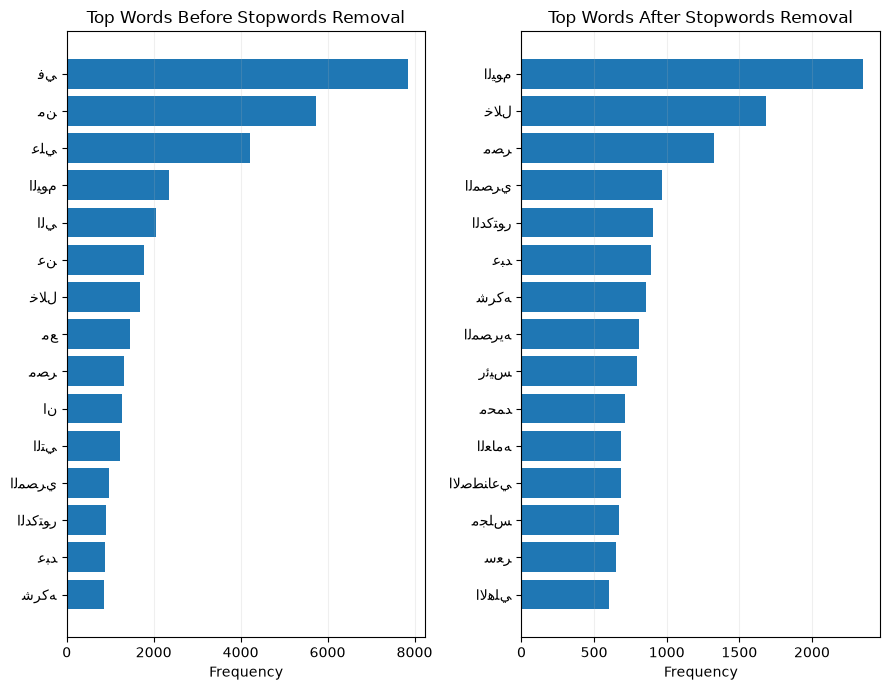

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9, 7))

datasets = [
    (before_counts, "Top Words Before Stopwords Removal"),
    (after_counts, "Top Words After Stopwords Removal")
]

for ax, (counts, title) in zip(axes, datasets):
    top_words = counts.most_common(15)

    words = [fix_arabic(word) for word, count in top_words]
    frequencies = [count for word, count in top_words]

    ax.barh(words[::-1], frequencies[::-1])

    ax.set_title(title)
    ax.set_xlabel("Frequency")
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

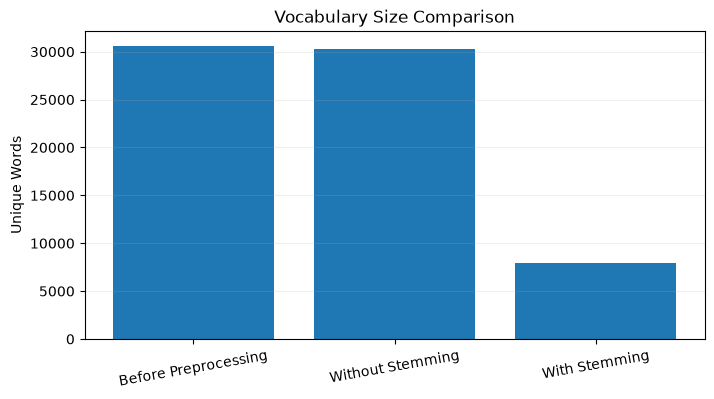

Before Preprocessing: 30,636 unique words
Without Stemming: 30,332 unique words
With Stemming: 7,928 unique words


In [19]:
stemmed_counts = get_word_frequencies(df["summary_stemmed"])

vocabulary_sizes = {
    "Before Preprocessing": len(before_counts),
    "Without Stemming": len(after_counts),
    "With Stemming": len(stemmed_counts)
}

plt.figure(figsize=(8, 4))

plt.bar(
    vocabulary_sizes.keys(),
    vocabulary_sizes.values()
)

plt.ylabel("Unique Words")
plt.title("Vocabulary Size Comparison")
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.2)
plt.show()

for name, size in vocabulary_sizes.items():
    print(f"{name}: {size:,} unique words")

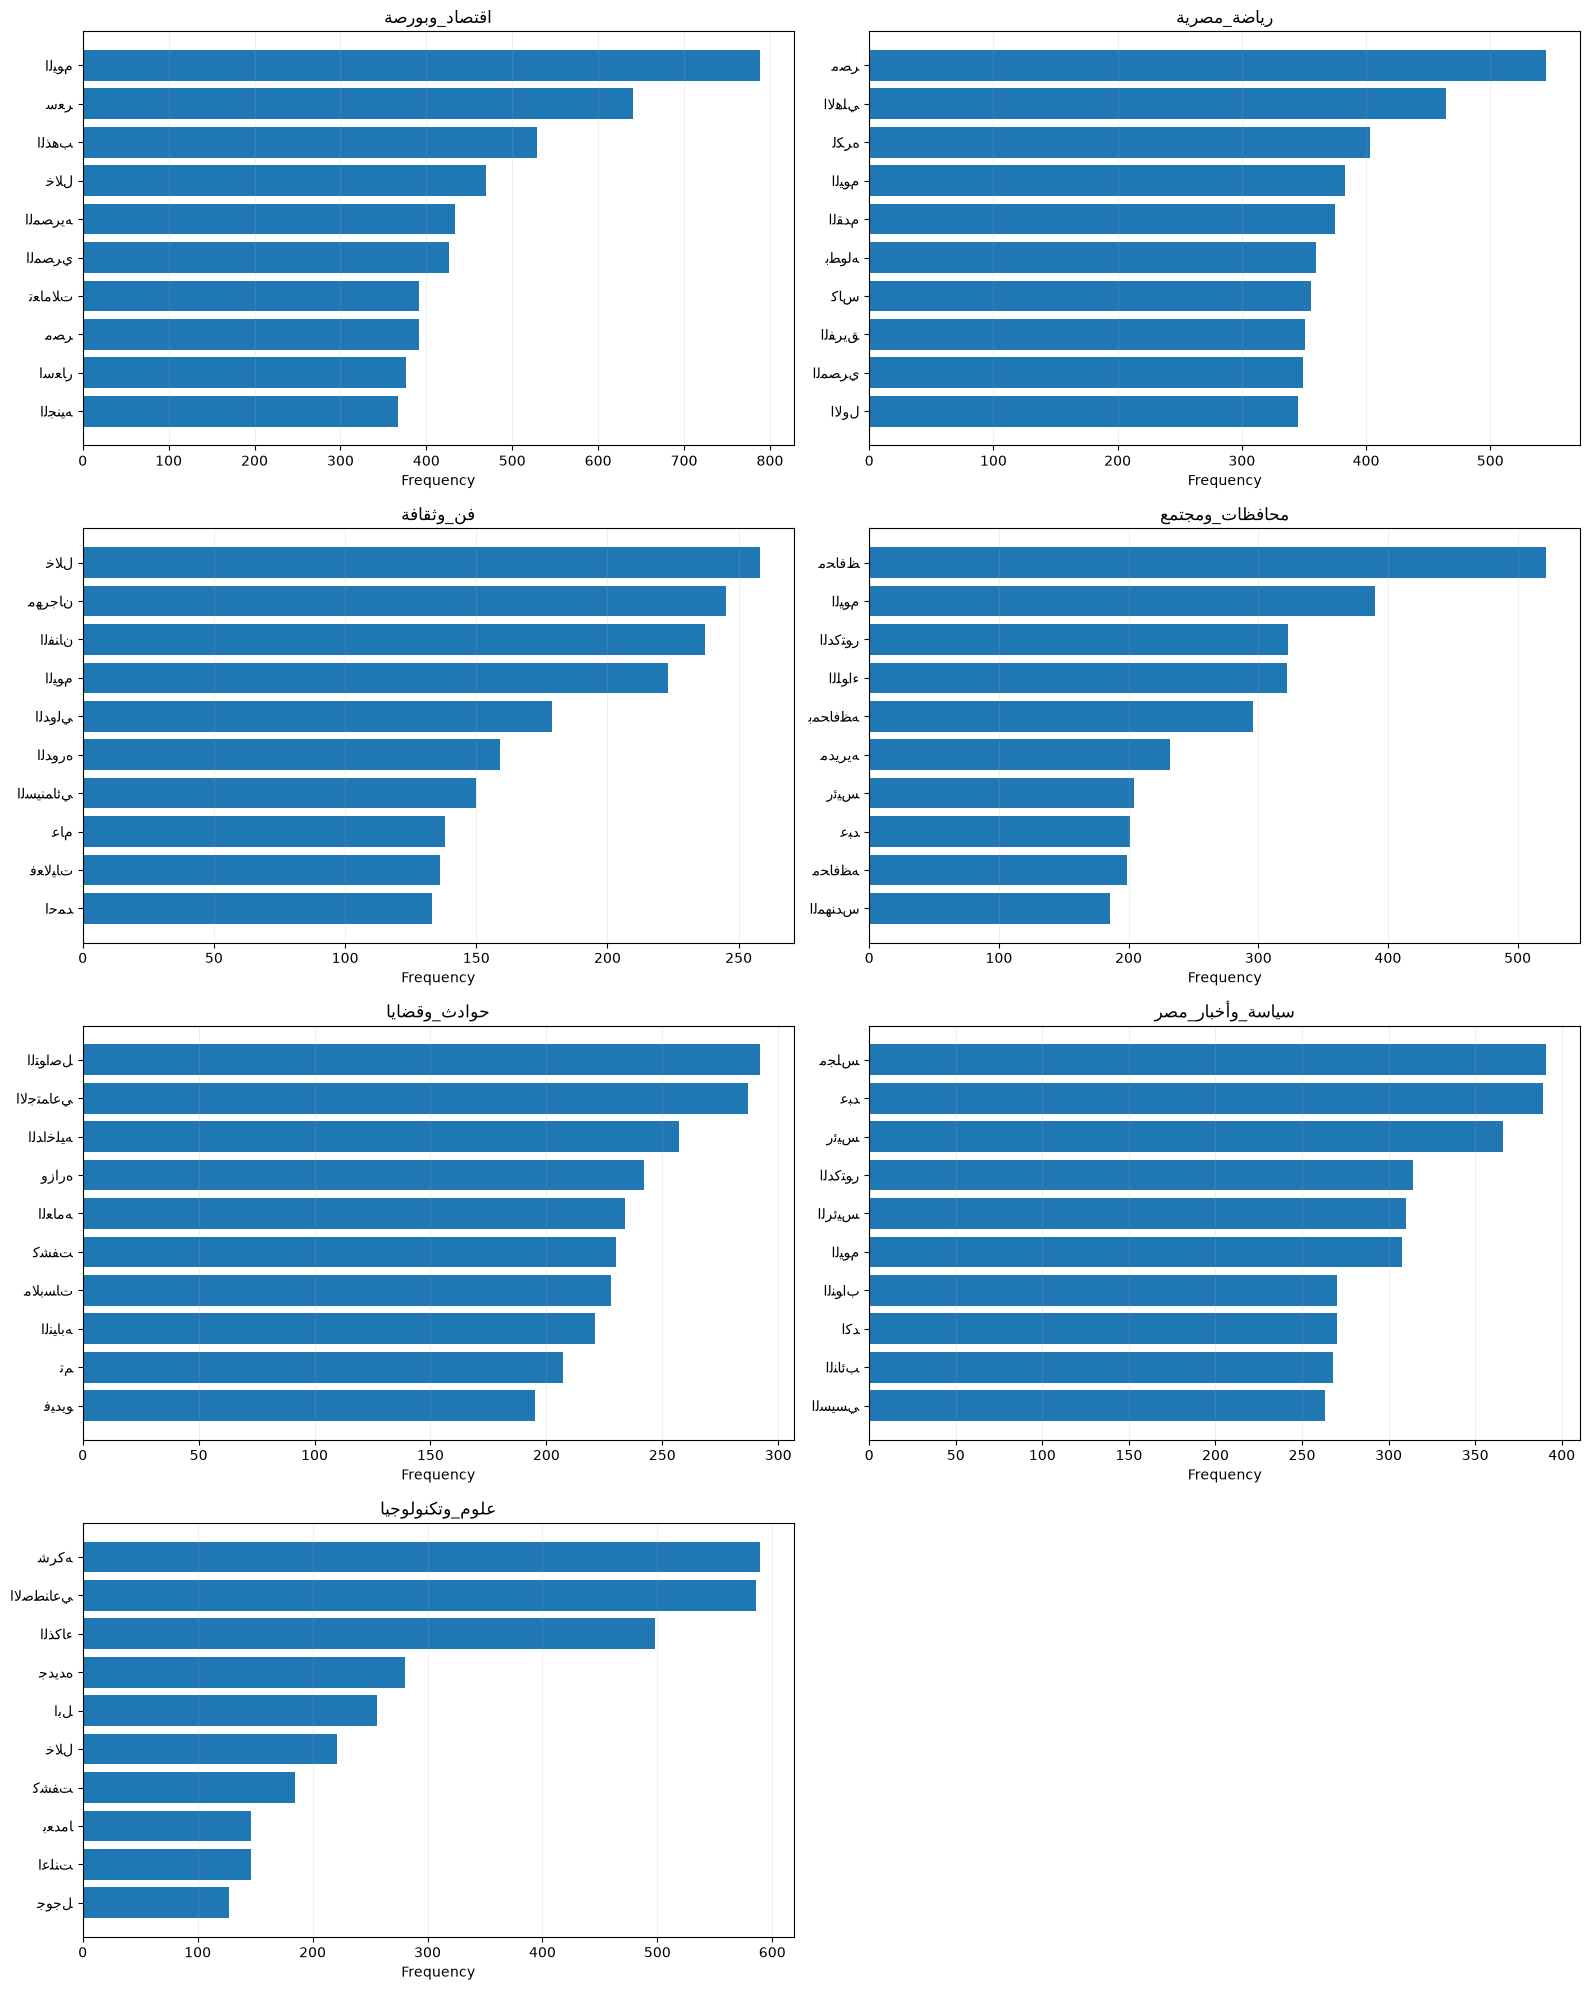

In [20]:
classes = df["category_label"].dropna().unique()

n_cols = 2
n_rows = (len(classes) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 5 * n_rows)
)

axes = np.array(axes).flatten()

for ax, category in zip(axes, classes):

    category_texts = df.loc[
        df["category_label"] == category,
        "summary_no_stem"
    ]

    counts = get_word_frequencies(category_texts)
    top_words = counts.most_common(10)

    words = [fix_arabic(word) for word, count in top_words]
    frequencies = [count for word, count in top_words]

    ax.barh(words[::-1], frequencies[::-1])

    ax.set_title(str(category))
    ax.set_xlabel("Frequency")
    ax.grid(axis="x", alpha=0.2)

for ax in axes[len(classes):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

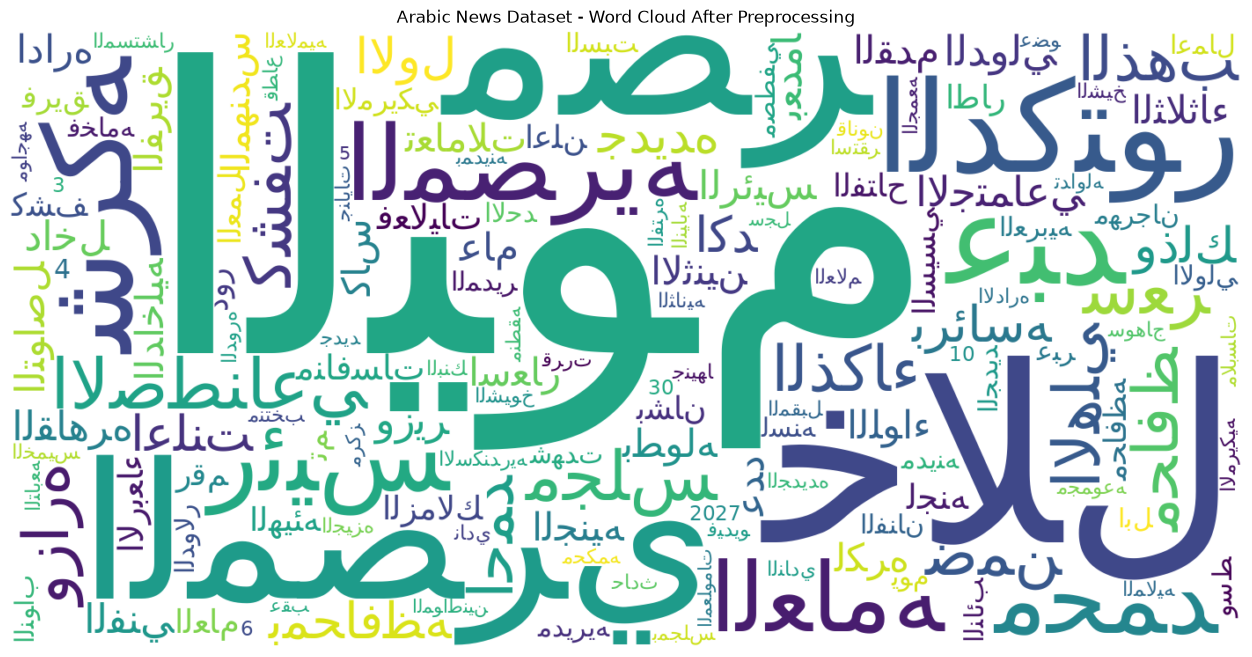

In [21]:
word_frequencies = get_word_frequencies(
    df["summary_no_stem"]
)

# Fix Arabic word rendering
arabic_frequencies = {
    fix_arabic(word): frequency
    for word, frequency in word_frequencies.items()
}

wordcloud = WordCloud(
    font_path=font_path,
    width=1400,
    height=700,
    background_color="white",
    max_words=150,
    collocations=False,
    random_state=42
).generate_from_frequencies(arabic_frequencies)

plt.figure(figsize=(16, 8))

plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Arabic News Dataset - Word Cloud After Preprocessing")

plt.show()

# Export the new df after preprocessing

In [22]:
df.drop(columns=["summary", "words_before", "words_after", "retained_percentage"],errors="ignore").to_csv(
    "../../datasets/c_text_youm7/youm7_nlp_preprocessed_data.csv",
    index=False,
    encoding="utf-8-sig"
)